In [82]:
# Pacotes de preparação dos dados
import pandas as pd
import numpy as np

# Pacotes gráficos
import matplotlib.pyplot as plt
import seaborn as sns


# Pacotes de Modelagem Estatística
from sklearn import tree
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

# Módulo de Análise Exploratória
import aed

In [83]:
#import base
df = pd.read_csv('dados_bom_pagador.csv')

In [84]:
display(df)

,Bom_Pagador,Renda_Mensal,Idade,Estado_Civil,Possui_Cartao_Credito,Escolaridade,Tempo_Emprego,Qtd_Filhos,Score_Credito,Historico_Inadimplencia,Utiliza_Limite_Cartao,Valor_Emprestimos,Tipo_Residencia,Trabalha_Formalmente
0,Sim,1688,21,Solteiro,Não,Pós-graduação,0,5,429,Nunca,97,40613,Financiada,Sim
1,Sim,12645,32,Viúvo,Não,Pós-graduação,19,4,580,Nunca,69,44769,Própria,Sim
2,Sim,13308,22,Solteiro,Não,Fundamental,4,2,346,Nunca,48,15783,Alugada,Sim
3,Sim,3376,20,Solteiro,Sim,Médio,7,2,355,Nunca,58,32615,Financiada,Sim
4,Não,12669,39,Divorciado,Não,Fundamental,4,1,866,Nunca,41,38217,Alugada,Sim
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,Sim,5108,21,Viúvo,Não,Pós-graduação,17,1,469,1 vez,21,16840,Alugada,Sim
96,Não,1617,55,Solteiro,Sim,Superior,24,2,614,2 ou mais,22,31578,Própria,Sim
97,Sim,2663,48,Divorciado,Sim,Pós-graduação,15,0,909,Nunca,10,19342,Alugada,Sim
98,Não,13097,50,Casado,Não,Pós-graduação,14,5,882,Nunca,78,48926,Alugada,Sim


In [85]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Bom_Pagador              100 non-null    object
 1   Renda_Mensal             100 non-null    int64 
 2   Idade                    100 non-null    int64 
 3   Estado_Civil             100 non-null    object
 4   Possui_Cartao_Credito    100 non-null    object
 5   Escolaridade             100 non-null    object
 6   Tempo_Emprego            100 non-null    int64 
 7   Qtd_Filhos               100 non-null    int64 
 8   Score_Credito            100 non-null    int64 
 9   Historico_Inadimplencia  100 non-null    object
 10  Utiliza_Limite_Cartao    100 non-null    int64 
 11  Valor_Emprestimos        100 non-null    int64 
 12  Tipo_Residencia          100 non-null    object
 13  Trabalha_Formalmente     100 non-null    object
dtypes: int64(7), object(7)
memory usage: 11.1+ 

In [86]:
df.describe().round(2)

,Renda_Mensal,Idade,Tempo_Emprego,Qtd_Filhos,Score_Credito,Utiliza_Limite_Cartao,Valor_Emprestimos
count,100.00,100.00,100.00,100.00,100.00,100.00,100.00
mean,8307.68,40.26,16.21,2.61,635.56,50.81,26713.27
std,4034.30,14.02,8.90,1.59,207.20,29.40,14117.50
min,1509.00,18.00,0.00,0.00,302.00,1.00,530.00
25%,4785.75,28.00,9.00,1.00,452.00,23.75,16238.25
50%,8787.00,42.00,18.00,2.00,596.50,49.50,25575.00
75%,11871.25,51.25,23.25,4.00,840.50,79.00,39991.25
max,14869.00,65.00,30.00,5.00,977.00,100.00,49517.00


In [87]:
df.describe(include='object')

,Bom_Pagador,Estado_Civil,Possui_Cartao_Credito,Escolaridade,Historico_Inadimplencia,Tipo_Residencia,Trabalha_Formalmente
count,100,100,100,100,100,100,100
unique,2,4,2,4,3,3,2
top,Sim,Viúvo,Sim,Superior,Nunca,Própria,Sim
freq,74,31,53,27,65,36,84


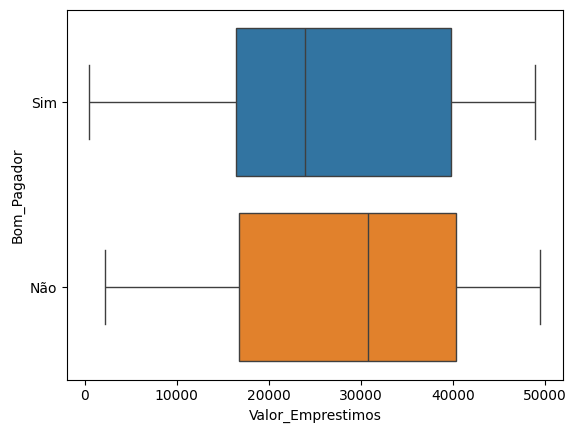

In [88]:
# vizuais do python sns
fig= sns.boxplot(data=df, x='Valor_Emprestimos', y='Bom_Pagador',hue='Bom_Pagador')

In [89]:
#valores vazisos
df.isna().sum()

,0
Bom_Pagador,0
Renda_Mensal,0
Idade,0
Estado_Civil,0
Possui_Cartao_Credito,0
Escolaridade,0
Tempo_Emprego,0
Qtd_Filhos,0
Score_Credito,0
Historico_Inadimplencia,0


In [90]:
df.index.duplicated().sum()

np.int64(0)

<Figure size 1000x3000 with 0 Axes>

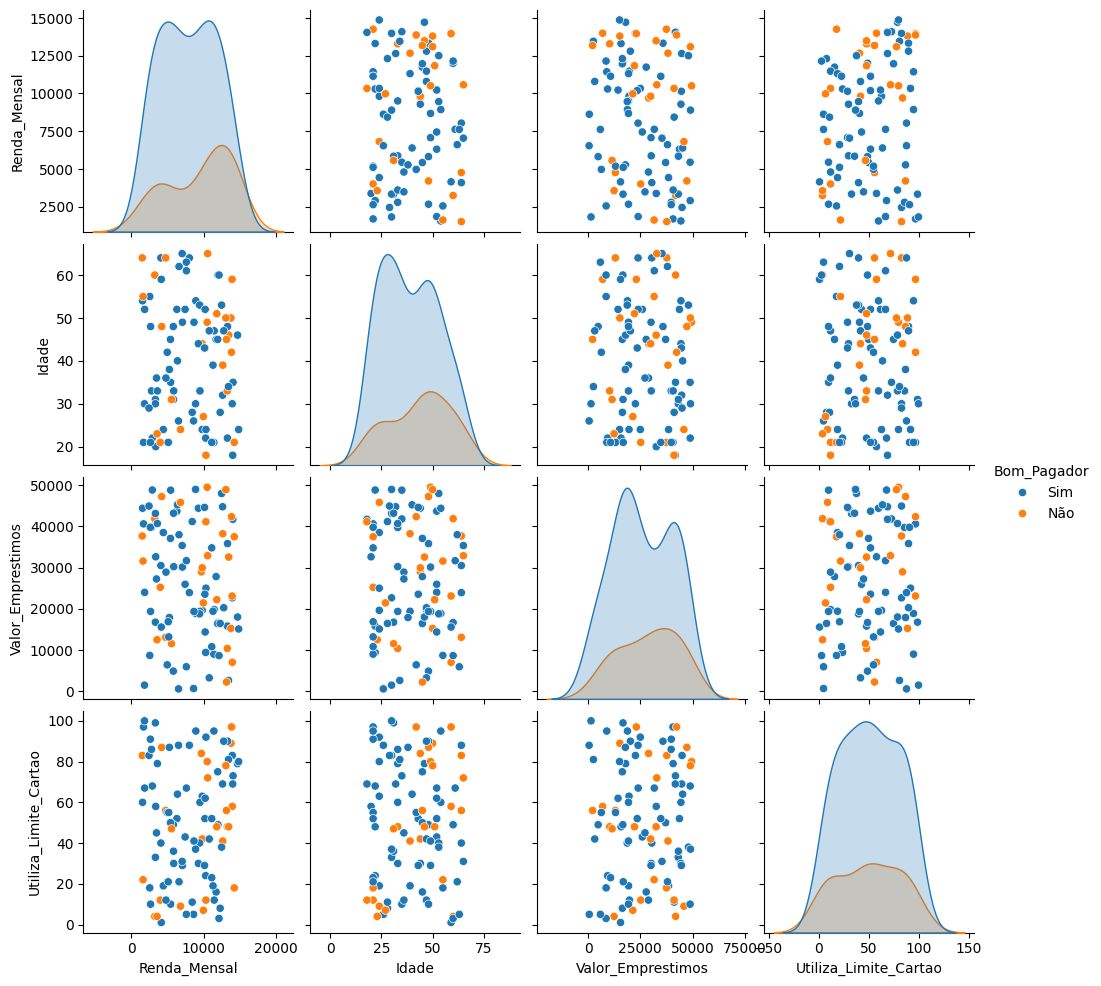

In [91]:
import matplotlib
matplotlib.use('module://ipykernel.pylab.backend_inline')
plt.figure(figsize=(10,30))
sns.pairplot(df[['Renda_Mensal','Bom_Pagador','Idade','Valor_Emprestimos','Utiliza_Limite_Cartao']] , hue='Bom_Pagador');

In [92]:
df['Target'] = np.where(df['Bom_Pagador'] == 'Sim', 1, 0)

df_iv = aed.analise_iv(df,
                          'Target')
df_iv.get_lista_iv()

/content/aed.py:110: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_num[nome_var] = pd.qcut(df_num[var],
/content/aed.py:32: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df2 = df_aux.pivot_table(values='target2',
/content/aed.py:32: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df2 = df_aux.pivot_table(values='target2',
/content/aed.py:32: FutureWarning: The default value of observed=False is deprecated and will change to

Target,IV
Variavel,
Bom_Pagador,9.21
Valor_Emprestimos,1.30
Utiliza_Limite_Cartao,1.19
Renda_Mensal,0.58
Tempo_Emprego,0.57
Score_Credito,0.55
Idade,0.20
Qtd_Filhos,0.19
Historico_Inadimplencia,0.05


In [93]:
df_iv.get_bivariada(var_escolhida='Valor_Emprestimos')

==> "Valor_Emprestimos" tem IV de 1.3


Target,Variavel,Var_Range,#Target_1,#Target_0,Total,%Freq,%Target_1,%Target_0,%Taxa_de_Target_1,Odds,LN(Odds),IV
0,Valor_Emprestimos,"(529.99, 8449.7]",8.0,2.0,10.0,10.0,10.81,7.69,80.0,1.41,0.34,0.01
1,Valor_Emprestimos,"(8449.7, 14113.4]",6.0,4.0,10.0,10.0,8.11,15.38,60.0,0.53,-0.63,0.05
2,Valor_Emprestimos,"(14113.4, 17554.0]",9.0,1.0,10.0,10.0,12.16,3.85,90.0,3.16,1.15,0.10
3,Valor_Emprestimos,"(17554.0, 20067.2]",10.0,0.0,10.0,10.0,13.51,0.01,100.0,1351.00,7.21,0.97
4,Valor_Emprestimos,"(20067.2, 25575.0]",6.0,4.0,10.0,10.0,8.11,15.38,60.0,0.53,-0.63,0.05
5,Valor_Emprestimos,"(25575.0, 31613.6]",7.0,3.0,10.0,10.0,9.46,11.54,70.0,0.82,-0.20,0.00
6,Valor_Emprestimos,"(31613.6, 37763.6]",6.0,4.0,10.0,10.0,8.11,15.38,60.0,0.53,-0.63,0.05
7,Valor_Emprestimos,"(37763.6, 41737.8]",8.0,2.0,10.0,10.0,10.81,7.69,80.0,1.41,0.34,0.01
8,Valor_Emprestimos,"(41737.8, 44786.5]",8.0,2.0,10.0,10.0,10.81,7.69,80.0,1.41,0.34,0.01
9,Valor_Emprestimos,"(44786.5, 49517.0]",6.0,4.0,10.0,10.0,8.11,15.38,60.0,0.53,-0.63,0.05


In [94]:
df_modelo = pd.get_dummies(df)
display(df_modelo)

,Renda_Mensal,Idade,Tempo_Emprego,Qtd_Filhos,Score_Credito,Utiliza_Limite_Cartao,Valor_Emprestimos,Target,Bom_Pagador_Não,Bom_Pagador_Sim,...,Escolaridade_Pós-graduação,Escolaridade_Superior,Historico_Inadimplencia_1 vez,Historico_Inadimplencia_2 ou mais,Historico_Inadimplencia_Nunca,Tipo_Residencia_Alugada,Tipo_Residencia_Financiada,Tipo_Residencia_Própria,Trabalha_Formalmente_Não,Trabalha_Formalmente_Sim
0,1688,21,0,5,429,97,40613,1,False,True,...,True,False,False,False,True,False,True,False,False,True
1,12645,32,19,4,580,69,44769,1,False,True,...,True,False,False,False,True,False,False,True,False,True
2,13308,22,4,2,346,48,15783,1,False,True,...,False,False,False,False,True,True,False,False,False,True
3,3376,20,7,2,355,58,32615,1,False,True,...,False,False,False,False,True,False,True,False,False,True
4,12669,39,4,1,866,41,38217,0,True,False,...,False,False,False,False,True,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,5108,21,17,1,469,21,16840,1,False,True,...,True,False,True,False,False,True,False,False,False,True
96,1617,55,24,2,614,22,31578,0,True,False,...,False,True,False,True,False,False,False,True,False,True
97,2663,48,15,0,909,10,19342,1,False,True,...,True,False,False,False,True,True,False,False,False,True
98,13097,50,14,5,882,78,48926,0,True,False,...,True,False,False,False,True,True,False,False,False,True


In [95]:
# target (Variaveis resposta)
y =  df_modelo['Target']

# Features (variaveis explicativas)
x = df_modelo.drop(['Target',
            'Bom_Pagador_Não',
            'Bom_Pagador_Sim'
            ],axis = 1)

In [116]:
#treinamento do modelo
#  split data
X_train, X_teste, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)
# treinar modelo
modelo = DecisionTreeClassifier(max_depth=3 , random_state=42)
modelo.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

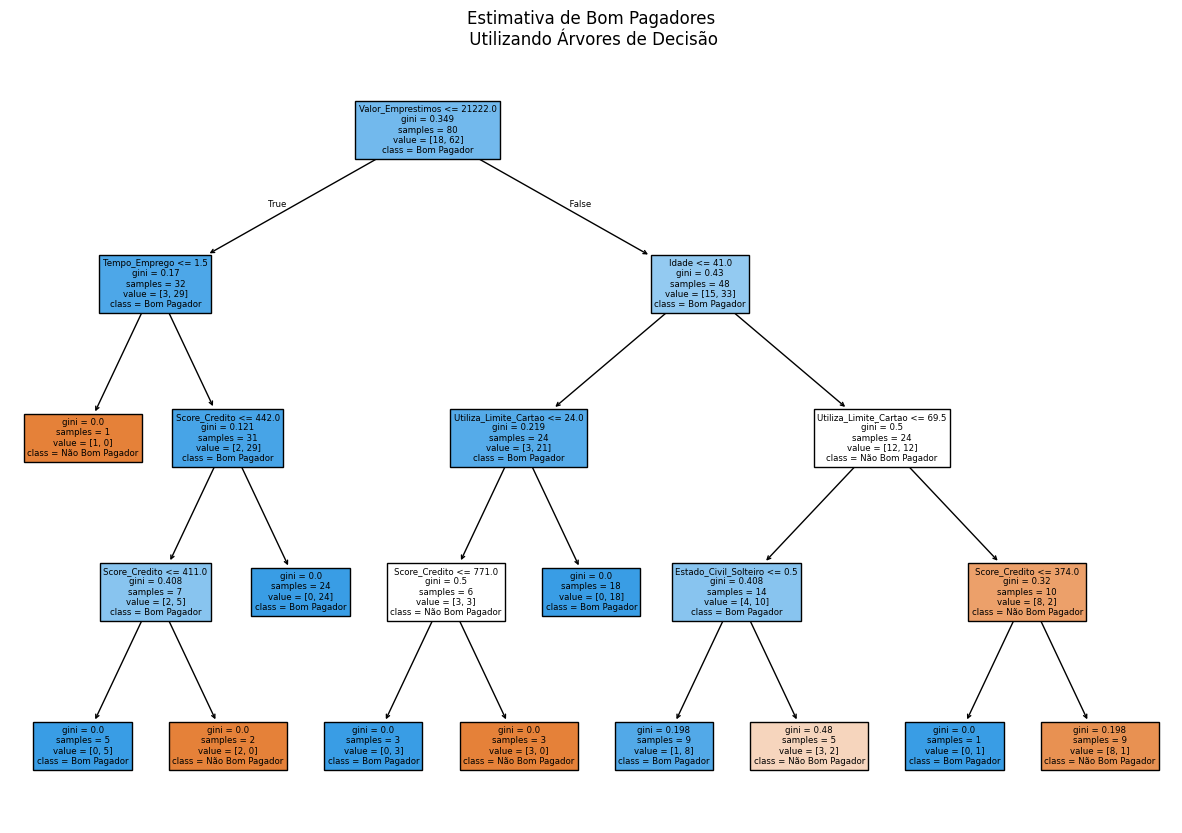

In [117]:
sns.reset_defaults()
%matplotlib inline
fig = plt.figure(figsize=(15,10))
features = list(x.columns)
tree.plot_tree(modelo,
               feature_names=features,
               class_names=['Não Bom Pagador','Bom Pagador'],
               filled=True);
plt.title("Estimativa de Bom Pagadores\n Utilizando Árvores de Decisão");

In [103]:
# Cálculo do desempenho do modelo: Acurácia
round(accuracy_score(y, modelo.predict(x)),2)

0.82

In [105]:
# Avaliação do modelo
y_pred = modelo.predict(X_teste)

In [106]:
print("Acurácia:", accuracy_score(y_test, y_pred))
print("Relatório de Classificação:\n", classification_report(y_test, y_pred))

Acurácia: 0.65
Relatório de Classificação:
               precision    recall  f1-score   support

           0       0.60      0.38      0.46         8
           1       0.67      0.83      0.74        12

    accuracy                           0.65        20
   macro avg       0.63      0.60      0.60        20
weighted avg       0.64      0.65      0.63        20

